# 外国人観光客の「伸びしろ」がある県はどこか？
### ― 宿泊データから、インバウンド誘客の重点候補を探す ―

| 項目 | 内容 |
|---|---|
| **作品タイトル** | 外国人観光客の「伸びしろ」がある県はどこか？ |
| **氏名** | ○○ ○○(ここに自分の氏名を記入) |
| **依頼元** | 地方観光振興機構(インターンとして参加) |
| **読み手** | 機構の理事会メンバー(データ分析の専門家ではない) |
| **調べたい問い** | 外国人宿泊者の割合が低く、しかも客室に余裕があり、自然の魅力もある県はどこか？ 来年度の誘客キャンペーンの重点候補としてどの県を提案できるか？ |

**使用データ**:`japan.csv`(47都道府県 × 約100項目)  
**使う列**:`外国人延べ宿泊者数`、`延べ宿泊者数`、`旅館営業施設客室数（ホテルを含む）`、`自然公園面積`、`総面積（北方地域及び竹島を除く）`  
**方針**:pandasは使わず、標準の `csv` モジュールとmatplotlibだけで分析します。

## 1. 考え方(分析の設計)

「伸びしろがある」を、データで次の3条件に言い換えます。

1. **外国人宿泊者の割合が低い** → まだ外国人に知られていない、または選ばれていない
2. **客室1室あたりの延べ宿泊者数が少ない** → 宿泊施設に受け入れの余裕がある(お客さんを増やしても部屋が足りなくなりにくい)
3. **自然公園の面積割合が高い** → 観光資源になりうる自然がある

3つとも「全国47県の中央値」を基準にして、条件をすべて満たす県を候補とします。

## 2. データの読み込み

標準ライブラリの `csv.DictReader` を使います。1行が1つの県の辞書になるので、列名で値を取り出せます。  
グラフに日本語を表示するため、フォントも設定します(環境にない場合は `japanize-matplotlib` を入れると表示できます)。

In [1]:
import csv
import statistics
import matplotlib.pyplot as plt

# 日本語フォントの設定(使えるものが自動で選ばれます)
plt.rcParams["font.family"] = ["Noto Sans CJK JP", "Yu Gothic", "Hiragino Sans", "Meiryo", "IPAexGothic", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False

with open("japan.csv", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

print("県の数:", len(rows))
print("列の数:", len(rows[0]))

県の数: 47
列の数: 92


## 3. データの確認

分析に使う5列について、①先頭の1件、②空欄や0がないかを確認します。これらがあると割り算がうまくいかないためです。

In [2]:
use_cols = ["都道府県", "外国人延べ宿泊者数", "延べ宿泊者数",
            "旅館営業施設客室数（ホテルを含む）", "自然公園面積", "総面積（北方地域及び竹島を除く）"]

print("【先頭1件】")
for c in use_cols:
    print(f"  {c}: {rows[0][c]}")

print()
print("【空欄・0・数値でない値のチェック】")
problems = 0
for r in rows:
    for c in use_cols[1:]:
        try:
            if float(r[c]) <= 0:
                print("  0以下:", r["都道府県"], c)
                problems += 1
        except ValueError:
            print("  数値でない:", r["都道府県"], c, repr(r[c]))
            problems += 1
print("問題のあった件数:", problems)

【先頭1件】
  都道府県: 北海道
  外国人延べ宿泊者数: 741410
  延べ宿泊者数: 24664930
  旅館営業施設客室数（ホテルを含む）: 122008
  自然公園面積: 880179
  総面積（北方地域及び竹島を除く）: 7842075

【空欄・0・数値でない値のチェック】
問題のあった件数: 0


## 4. 分析① 指標をつくる

都道府県どうしを公平に比べるため、総量ではなく**割合や1あたりの値**に直します。

- `外国人比率(%)` = 外国人延べ宿泊者数 ÷ 延べ宿泊者数 × 100
- `客室あたり宿泊者数` = 延べ宿泊者数 ÷ 客室数(値が小さいほど客室に余裕がある目安)
- `自然公園率(%)` = 自然公園面積 ÷ 総面積 × 100

In [3]:
data = []
for r in rows:
    total = float(r["延べ宿泊者数"])
    data.append({
        "県": r["都道府県"],
        "外国人比率": float(r["外国人延べ宿泊者数"]) / total * 100,
        "客室あたり": total / float(r["旅館営業施設客室数（ホテルを含む）"]),
        "自然公園率": float(r["自然公園面積"]) / float(r["総面積（北方地域及び竹島を除く）"]) * 100,
    })

# 全国の中央値(基準線)
med_foreign = statistics.median(d["外国人比率"] for d in data)
med_room    = statistics.median(d["客室あたり"] for d in data)
med_nature  = statistics.median(d["自然公園率"] for d in data)

print(f"外国人比率の中央値      : {med_foreign:.2f} %")
print(f"客室あたり宿泊者数の中央値: {med_room:.1f} 人泊/室")
print(f"自然公園率の中央値      : {med_nature:.1f} %")

外国人比率の中央値      : 0.96 %
客室あたり宿泊者数の中央値: 190.3 人泊/室
自然公園率の中央値      : 14.8 %


## 5. 分析② 外国人比率が低い県のランキング

まず条件1だけで、外国人比率が低い順に10県を並べます。右側の○×は、他の2条件を満たすかどうかです。

In [4]:
ranked = sorted(data, key=lambda d: d["外国人比率"])

print(f"{'順位':>2} {'県':<5} {'外国人比率':>8} {'客室あたり':>9} {'自然公園率':>9}   余裕 自然")
for i, d in enumerate(ranked[:10], start=1):
    room_ok = "○" if d["客室あたり"] < med_room else "×"
    nat_ok  = "○" if d["自然公園率"] > med_nature else "×"
    print(f"{i:>3} {d['県']:<5} {d['外国人比率']:>7.2f}% {d['客室あたり']:>9.1f} {d['自然公園率']:>8.1f}%    {room_ok}    {nat_ok}")

順位 県        外国人比率     客室あたり     自然公園率   余裕 自然
  1 高知県      0.34%     187.8      6.7%    ○    ×
  2 島根県      0.34%     226.8      6.0%    ×    ×
  3 福島県      0.48%     150.4     13.1%    ○    ×
  4 福井県      0.49%     143.0     14.8%    ○    ×
  5 秋田県      0.49%     156.0     10.6%    ○    ×
  6 鳥取県      0.50%     173.8     14.0%    ○    ×
  7 岩手県      0.53%     194.1      4.7%    ×    ×
  8 鹿児島県     0.58%     166.3     13.6%    ○    ×
  9 栃木県      0.58%     209.2     20.8%    ×    ○
 10 群馬県      0.64%     190.7     14.0%    ×    ×


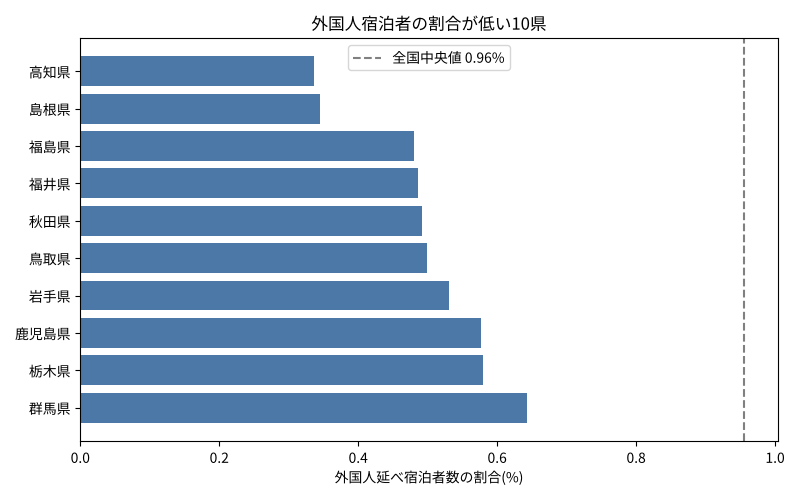

In [5]:
bottom = ranked[:10][::-1]   # 横棒グラフは下から描くので逆順に
names  = [d["県"] for d in bottom]
values = [d["外国人比率"] for d in bottom]

plt.figure(figsize=(8, 5))
plt.barh(names, values, color="#4C78A8")
plt.axvline(med_foreign, color="gray", linestyle="--", label=f"全国中央値 {med_foreign:.2f}%")
plt.xlabel("外国人延べ宿泊者数の割合(%)")
plt.title("外国人宿泊者の割合が低い10県")
plt.legend()
plt.tight_layout()
plt.show()

**読み取り**:外国人比率が低い県は、東北・中国・四国・九州などに多く見られます。ただし、割合が低いだけでは「伸びしろ」とは言えません。自然などの魅力や、客室の余裕もあわせて見ます。

## 6. 分析③ 3つの条件で候補を絞る

3条件(外国人比率が中央値より低い/客室あたり宿泊者数が中央値より低い/自然公園率が中央値より高い)をすべて満たす県を抜き出します。

In [6]:
candidates = [d for d in data
              if d["外国人比率"] < med_foreign
              and d["客室あたり"] < med_room
              and d["自然公園率"] > med_nature]

candidates.sort(key=lambda d: d["外国人比率"])
print("3条件をすべて満たす県:", len(candidates), "件")
for d in candidates:
    print(f"  {d['県']}:外国人比率 {d['外国人比率']:.2f}%、客室あたり {d['客室あたり']:.1f}、自然公園率 {d['自然公園率']:.1f}%")

3条件をすべて満たす県: 3 件
  山形県:外国人比率 0.64%、客室あたり 169.5、自然公園率 16.7%
  新潟県:外国人比率 0.85%、客室あたり 151.8、自然公園率 25.2%
  富山県:外国人比率 0.91%、客室あたり 173.8、自然公園率 29.6%


## 7. 分析④ 全国の中での位置を散布図で確認

横軸が「客室あたり宿泊者数」、縦軸が「外国人比率」です。左下ほど「外国人が少なく、客室に余裕がある」県です。  
点の大きさは自然公園率、赤い点が3条件を満たす候補です。東京など外国人比率が極端に高い県があるため、縦軸は対数目盛にしています。

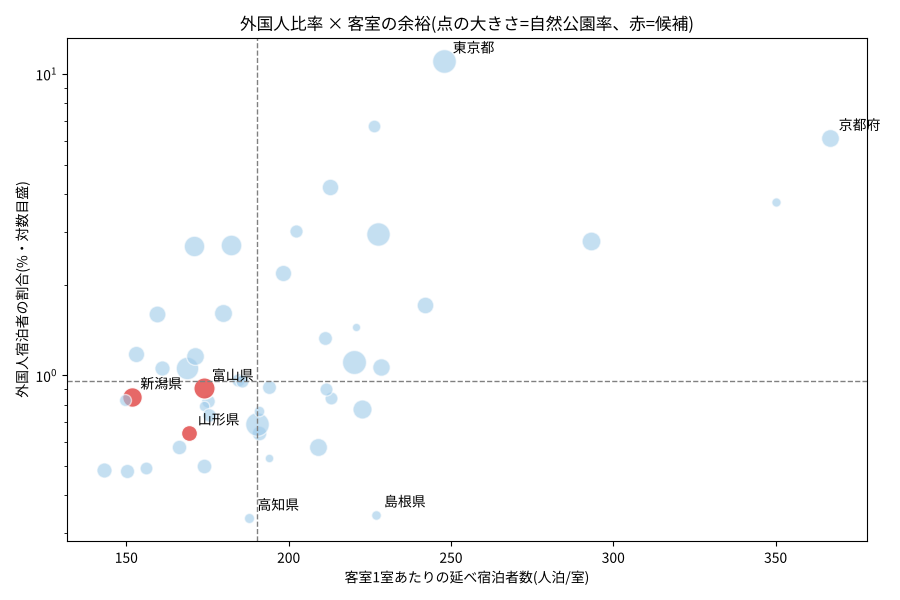

In [7]:
cand_names = [d["県"] for d in candidates]

plt.figure(figsize=(9, 6))
for d in data:
    is_cand = d["県"] in cand_names
    plt.scatter(d["客室あたり"], d["外国人比率"],
                s=d["自然公園率"] * 8,
                color="#E45756" if is_cand else "#9ECAE9",
                alpha=0.9 if is_cand else 0.6,
                edgecolor="white")
    if is_cand or d["県"] in ["東京都", "京都府", "高知県", "島根県"]:
        plt.annotate(d["県"], (d["客室あたり"], d["外国人比率"]),
                     textcoords="offset points", xytext=(6, 6), fontsize=10)

plt.axvline(med_room, color="gray", linestyle="--", linewidth=1)
plt.axhline(med_foreign, color="gray", linestyle="--", linewidth=1)
plt.yscale("log")
plt.xlabel("客室1室あたりの延べ宿泊者数(人泊/室)")
plt.ylabel("外国人宿泊者の割合(%・対数目盛)")
plt.title("外国人比率 × 客室の余裕(点の大きさ=自然公園率、赤=候補)")
plt.tight_layout()
plt.show()

## 8. わかったこと

- **外国人比率が最も低いのは高知県・島根県(いずれも約0.34%)** で、全国中央値(約0.96%)の3分の1ほどです。ただし、この2県は「客室の余裕」「自然公園率」のどちらかを満たさず、ランキング上位10県のうち3条件を同時に満たす県はありませんでした。
- **3条件をすべて満たすのは山形県・新潟県・富山県の3県**です。
  - 山形県:外国人比率が3県で最も低い(約0.64%)。客室あたり宿泊者数は約170人泊で余裕がある。
  - 新潟県:客室あたり宿泊者数が約152人泊と3県で最も低く、受け入れの余裕が大きい。自然公園率も約25%。
  - 富山県:自然公園率が約30%と3県で最も高く、自然資源が豊富。
- 散布図では、3県とも「外国人が少なく、客室に余裕がある」左下側に位置し、東京・京都・大阪のような都市部とは大きく離れています。外国人宿泊は一部の大都市に集中していることもわかります。

## 9. 組織への提案

1. **来年度の重点候補として、山形・新潟・富山の3県を提案します。** 外国人比率が低く、客室にも余裕があるため、誘客施策を打っても宿泊施設が満室で受け入れられない、という事態が起きにくいと考えられます。
2. **県ごとに強みを分けた訴求を行います。**
   - 富山:自然公園の面積が大きいため、自然体験を前面に出す。
   - 新潟:客室に余裕があるため、団体・長期滞在向けの誘客を試す。
   - 山形:外国人比率が最も低いため、まず認知度を上げる情報発信(多言語サイト・SNS)から始める。
3. **まず小規模な試行(パイロット)を行い、効果を測ります。** 実施前後で「外国人比率」と「外国人延べ宿泊者数」を、このNotebookと同じ方法で比べれば、成果を数字で報告できます。

### 注意点(この分析の限界)
- **データの年次が不明です。** 東京でも外国人比率が約11%にとどまることから、外国人旅行者が大きく減った時期のデータの可能性があります。提案の前に、最新年のデータで同じ分析を再実行して確認する必要があります。
- 「客室あたり宿泊者数」は、客室の稼働の余裕を見るための**簡易的な目安**です。施設の規模や季節による偏りは考慮していません。
- 自然公園の面積が大きいことは、観光の魅力を保証するものではありません。アクセスや宿泊の質、食・文化資源なども、現地調査で確認が必要です。
- 中央値を基準にした3条件の絞り込みは一つのやり方です。基準を変えると候補も変わる可能性があります(たとえば基準を厳しくすると、候補はさらに絞られます)。

### 今後の発展
- 同じ指標を、人口あたりの博物館数や1人当たり県民所得など、他の列とも組み合わせてみる。
- 緯度経度のデータを用意して、候補県を地図上に示す。